<a href="https://colab.research.google.com/github/shaikfouziya145-swf/bizbot/blob/main/WebAdOptimization_UpperConfidenceBound_ReinforcementLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dataset25.csv to dataset25.csv


In [ ]:
dataset = pd.read_csv('dataset25.csv')
print(dataset.shape)
print(dataset.head(5))

(10000, 10)
   Ad 1  Ad 2  Ad 3  Ad 4  Ad 5  Ad 6  Ad 7  Ad 8  Ad 9  Ad 10
0     1     0     0     0     1     0     0     0     1      0
1     0     0     0     0     0     0     0     0     1      0
2     0     0     0     0     0     0     0     0     0      0
3     0     1     0     0     0     0     0     1     0      0
4     0     0     0     0     0     0     0     0     0      0


In [ ]:
import math
observations = 10000
no_of_Ads = 10
ads_selected = []
numbers_of_selections_of_each_ads = [0] * no_of_Ads
sums_of_rewards_of_each_ads = [0] * no_of_Ads
total_reward = 1
for n in range(1, observations):
    ad = 0
    max_upper_bound = 1
    for i in range(0, no_of_Ads):
        if (numbers_of_selections_of_each_ads[i] > 0):
            average_reward = sums_of_rewards_of_each_ads[i] / numbers_of_selections_of_each_ads[i]
            delta_i = math.sqrt(3/2 * math.log(n + 1) / numbers_of_selections_of_each_ads[i])
            upper_bound = average_reward + delta_i
        else:
            upper_bound = 1e400
        if upper_bound > max_upper_bound:
            max_upper_bound = upper_bound
            ad = i
    ads_selected.append(ad)
    numbers_of_selections_of_each_ads[ad] = numbers_of_selections_of_each_ads[ad] + 1
    reward = dataset.values[n, ad]
    sums_of_rewards_of_each_ads[ad] = sums_of_rewards_of_each_ads[ad] + reward
    total_reward = total_reward + reward

print("Rewards by Ads = ",sums_of_rewards_of_each_ads)
print("Total Rewards by UCB = ",total_reward)
print("Ads selected at each round:",ads_selected)

Rewards by Ads =  [np.int64(1671), np.int64(0), np.int64(1), np.int64(4), np.int64(13), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0)]
Total Rewards by UCB =  1691
Ads selected at each round: [1, 2, 3, 4, 5, 6, 7, 8, 9, 1, 2, 3, 4, 5, 6, 7, 8, 9, 3, 3, 1, 2, 4, 5, 6, 7, 7, 8, 9, 3, 7, 1, 2, 4, 5, 6, 8, 9, 3, 7, 1, 2, 4, 4, 5, 6, 8, 9, 3, 4, 7, 1, 2, 5, 6, 8, 9, 3, 4, 7, 1, 2, 5, 6, 8, 9, 3, 4, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 5, 6, 8, 9, 0, 0, 3, 4, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 2, 5, 6, 8, 9, 0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 4, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 0, 0, 

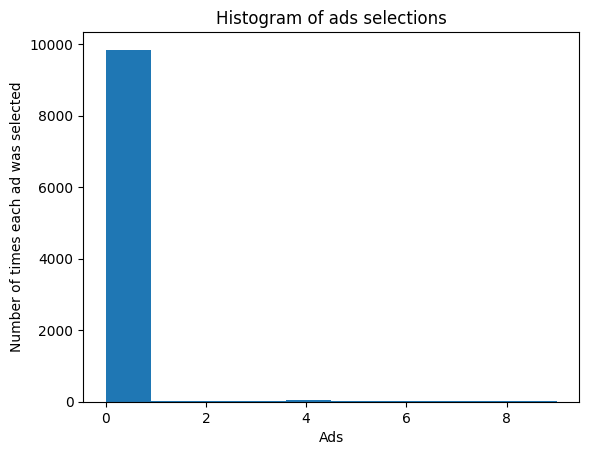

In [ ]:
plt.hist(ads_selected)
plt.title('Histogram of ads selections')
plt.xlabel('Ads')
plt.ylabel('Number of times each ad was selected')
plt.show()

## Explanation of Upper Confidence Bound (UCB) Implementation

### 1. Context & Setup
* **Goal**: Maximize the total click-through rate (CTR) or total reward by selecting the most optimal advertisement among 10 available options over 10,000 rounds.
* **Exploration vs. Exploitation**: This is a classic Multi-Armed Bandit problem. Pure exploitation means always selecting the ad that currently has the highest historical reward. Pure exploration means testing random ads to see if they perform better. UCB balances both by calculating an upper confidence bound for each ad.

### 2. How the Algorithm Works
For each round $n$ from $1$ to $10,000$, we calculate the following for each ad $i$:

1. **Average Reward ($\_r_i$):**
   $$\bar{r}_i(n) = \frac{\text{sums\_of\_rewards\_of\_each\_ads}[i]}{\text{numbers\_of\_selections\_of\_each\_ads}[i]}$$
   This represents our current estimate of how good the ad is (exploitation).

2. **Confidence Interval ($\Delta_i$):**
   $$\Delta_i(n) = \sqrt{\frac{3}{2} \frac{\ln(n)}{N_i(n)}}$$
   This represents our uncertainty. If an ad $i$ hasn't been selected many times (small $N_i(n)$), $\Delta_i$ will be large (exploration).

3. **Upper Confidence Bound:**
   $$\text{UCB} = \bar{r}_i(n) + \Delta_i(n)$$
   We choose the ad $i$ that maximizes this value. If an ad hasn't been chosen yet ($N_i(n) = 0$), we set its upper bound to a very high default value ($10^{400}$) to force the algorithm to explore it at least once.

### 3. Key Observations from the Outputs
* **Winning Ad**: The `sums_of_rewards_of_each_ads` shows that **Ad 1** (index `0` in python list, but labeled as Ad 1) accumulated the highest number of rewards (`1671`), while most other ads ended with close to $0$ rewards.
* **Total Reward**: The total reward achieved by this UCB run is `1691` clicks out of 10,000 rounds.
* **Histogram**: The histogram demonstrates that the algorithm successfully identified **Ad 1** early on and prioritized selecting it (exploiting), avoiding wasting rounds on non-performing ads.